# Clinical Decision Support: Medical RAG 

Built by combining the team's files, with no existing code changed:
- **Hybrid_ChromaDB_BM25**: setup, data loading, cleaning, duplicate removal, chunking, Chroma embeddings, hybrid BM25 + Chroma retrieval, Gemma 3 generation, 50-question run, batch LLM-as-a-Judge, score chart
- **Draft (1)**: single-question ask and single-question LLM-as-a-Judge test
- **rag_ui.py**: the user interface (written to disk by the cell in the UI section)


In [1]:
!pip install langchain-chroma
!pip install langchain-retrievers-bm25
!pip install langchain-classic
!pip install langchain-groq langchain-huggingface
!pip install -qU langchain langgraph langchain_core langchain_community chromadb sentence-transformers langchain-openai biopython langchain_huggingface faiss-cpu sentence_transformers transformers accelerate pypdf rank_bm25

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 100.7 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 71.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 72.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 127.4 MB/s  0:00:00
  Attempting uninstall: python-dateutil
    Found existing installation: python-dateutil 2.9.0.post0
    Uninstalling python-dateutil-2.9.0.post0:
      Successfully uninstalled python-dateutil-2.9.0.post0
  Attempting uninstall: pydantic-core━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/21 [python-dateutil]
    Found existing installation: pydantic_core 2.50.1━━━━━━━━━  2/21 [python-dateutil]
    Uninstalling pydantic_core-2.50.1:━━━━━━━━━━━━━━━━━━━━━━━━  2/21 [python-dateutil]
      Successfully uninstalled pydantic_core-2.50.1━━━━━━━━━━━  2/21 [python-dateutil]
  Attempting uninstall: opentelemetry-api━━━━━━━━━━━━━━━━━━━━━━━━━  3/21 [pydantic-core]
    Found existing installation: openteleme

In [2]:
from datasets import load_dataset
import pandas as pd

In [3]:
# 1. Load the dataset

dataset_covid = load_dataset("galileo-ai/ragbench", "covidqa", split="train")
dataset_pubmed = load_dataset("galileo-ai/ragbench", "pubmedqa", split="train")
# 2. Select only the requested columns
columns_to_keep = ["question", "documents", "response"]
filtered_dataset_covid = dataset_covid.select_columns(columns_to_keep)
filtered_dataset_pubmed = dataset_pubmed.select_columns(columns_to_keep)

README.md:   0%|          | 0.00/24.7k [00:00<?, ?B/s]

covidqa/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 4.20MB            

covidqa/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

covidqa/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  854kB            

covidqa/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

covidqa/validation-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B /  913kB            

... (9 outputs left out)

pubmedqa/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/19600 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2450 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2450 [00:00<?, ? examples/s]

In [4]:
filtered_dataset_pubmed.to_csv("pubmedqa_training.csv", index=False)

print("Download complete! Saved to pubmedqa_training.csv")

filtered_dataset_covid.to_csv("covidqa_training.csv", index=False)

print("Download complete! Saved to covid_training.csv")

Creating CSV from Arrow format:   0%|          | 0/20 [00:00<?, ?ba/s]

Download complete! Saved to pubmedqa_training.csv


Creating CSV from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Download complete! Saved to covid_training.csv


In [5]:
from datasets import load_dataset, concatenate_datasets
df_pubmed = pd.DataFrame(filtered_dataset_pubmed)
df_covid = pd.DataFrame(filtered_dataset_covid)

# Combine them into a single Dataset object
combined_dataset = concatenate_datasets([filtered_dataset_covid, filtered_dataset_pubmed])

# Convert the combined dataset into a single DataFrame
df_combined = pd.DataFrame(combined_dataset)
print(f"Total combined rows: {len(df_combined)}")

Total combined rows: 20852


In [6]:
# 1. Authenticate using Kaggle Secrets
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login
user_secrets = UserSecretsClient()

try:

    hf_token = user_secrets.get_secret("KAGGLE_API_TOKEN")

    # This line is crucial—it passes the token directly to the environment
    os.environ["KAGGLE_API_TOKEN"] = hf_token
    print("Success: KAGGLE_API_TOKEN set in environment.")
except Exception as e:
    print("Warning: KAGGLE_API_TOKEN secret not found or could not be loaded.")
    

Clean the data

In [7]:
import re
from langchain_core.documents import Document
# ==========================================
# Task 1: DATA CLEANING AND TEXT SANITIZATION
# ==========================================
def clean_text(text: str) -> str:
    """
    Cleans raw document snippets by trimming whitespaces, fixing formatting leaks,
    and removing brackets or list leftovers typical in semi-structured text.
    """
    if not text:
        return ""
    # Remove leading/trailing formatting like literal brackets if any leak
    text = re.sub(r'^\[|\]$', '', text.strip())
    # Standardize multiple tabs/newlines/spaces down into a single space
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Compile cleaned document groups into individual standard LangChain Documents
langchain_docs = []
for index, row in df_combined.iterrows():
    # dataset documents is a list of context snippets
    for text_snippet in row["documents"]:
        cleaned = clean_text(text_snippet)
        if cleaned:
            # Propagate the corresponding row metadata for trace auditing
            langchain_docs.append(Document(
                page_content=cleaned,
                metadata={"row_index": index, "source": "pubmedqa"}
            ))

# Extract original lists safely
pages = df_combined["documents"]
print("Combined \n",pages)
questions_pubmed = df_pubmed["question"]
print("Pubmed question ",questions_pubmed)
answers_pubmed = df_pubmed["response"]
print("Pubmed answer ",answers_pubmed)
questions_covid = df_covid["question"]
print("Pubmed question ",questions_covid)
answers_covid = df_covid["response"]
print("Pubmed answer ",answers_covid)

print(f"Initial raw document objects parsed and cleaned: {len(langchain_docs)}")

Combined 
 0        [Title: Emergent severe acute respiratory dist...
1        [Title: Gene Knockdowns in Adult Animals: PPMO...
2        [Title: MERS coronavirus: diagnostics, epidemi...
3        [Title: Kinome-Wide siRNA Screening Identifies...
4        [Title: Pandemic Influenza Due to pH1N1/2009 V...
                               ...                        
20847    [The decision to perform immediate deep inferi...
20848    [Overall 90-day reoperation rate after LT was ...
20849    [To evaluate the accuracy of the Menopause Rat...
20850    [The Svalbard endemic aphid Acyrthosiphon sval...
20851    [18 cases were included (halo n = 8/sevo n = 1...
Name: documents, Length: 20852, dtype: object
Pubmed question  0        Is there a functional neural correlate of indi...
1        Can we use the Omron T9P automated blood press...
2        Intraabdominal vascular injury: are we getting...
3        Hand grip and pinch strength in patients with ...
4        Is Canada ready for patient acce

# **Remove duplicate document**

In [10]:
pages = df_combined["documents"]
print("Before removing duplicates",pages.count())
pages=pages.drop_duplicates()
print("After removing duplicates",pages.count())

Before removing duplicates 20852
After removing duplicates 11018


In [11]:
from langchain_core.documents import Document
# Convert raw string lists from the 'pages' Series into LangChain Document objects, removing duplicates
langchain_docs = []
for doc_list in pages:
    # Deduplicate the inner list while preserving original document order
    deduplicated_doc_list = list(dict.fromkeys(doc_list))

    for text in deduplicated_doc_list:
        langchain_docs.append(Document(page_content=text))

print(f"Initial raw document objects parsed and cleaned: {len(pages)}")

Initial raw document objects parsed and cleaned: 11018


## **Chunking**

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Fixed Size Chunking
# chunk_size    : max characters per chunk
# chunk_overlap : shared characters between consecutive chunks
splitter = RecursiveCharacterTextSplitter(
    chunk_size=1200,
    chunk_overlap=200
)

chunks = splitter.split_documents(langchain_docs)
print(f"Total chunks created: {len(chunks)}")
print("Chunk 1:")
print(chunks[0].page_content)
print("Chunk 2:")
print(chunks[1].page_content)
print("\nchunk_size=1200, chunk_overlap=200")
print("The splitter attempts to preserve up to 200 characters of context between consecutive chunks.")
print("RecursiveCharacterTextSplitter also tries to respect natural text boundaries such as paragraphs and words.")

Total chunks created: 53938
Chunk 1:
Title: Emergent severe acute respiratory distress syndrome caused by adenovirus type 55 in immunocompetent adults in 2013: a prospective observational study
Passage: Recent studies have shown that the immune system plays a crucial role in the clearance of HAdV viremia and survival of the host . Chen et al. reported that, in the acute phase of HAdV-55 infection, patients with severe disease may have high levels of dendritic cells and Th17 cells . In our study, the only patient who recovered from severe infection had higher T-cell counts. Three of the five patients had relatively low T-cell counts when admitted. Our results suggest that these three patients may have been relatively immunocompromised and that a lower T-cell count may be a risk
Chunk 2:
Title: Human adenovirus type 7 infection causes a more severe disease than type 3
Passage: Laboratory findings for the HAdV-7-positive inpatients were also significantly different from those infected by 

### **Embedding**

In [13]:
#from langchain_community.vectorstores import FAISS
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
import torch

# 1. Check if GPU is available and set device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# 2. Configure embedding model to use GPU and a larger batch size
model_kwargs = {'device': device}
encode_kwargs = {'batch_size': 128} # Increase batch size (e.g., 64, 128, or 256) for faster processing

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    model_kwargs=model_kwargs,
    encode_kwargs=encode_kwargs
)
print("Embedding model loaded.")

# Add chunk IDs
for i, chunk in enumerate(chunks):
    chunk.metadata["chunk_id"] = i + 1

# Instantiate local Chroma Vector database in-memory
# (For persistent storage, add `persist_directory="./chroma_db"`)
chroma_vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embeddings
)
print("Chroma DB vector store indexing complete.")

Using device: cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded.
Chroma DB vector store indexing complete.


## **Retrieval**

In [18]:
# ==========================================
# Task 2: RETRIEVAL VIA HYBRID SEARCH (BM25 + CHROMA)
# ==========================================
from langchain_community.retrievers import BM25Retriever
#from langchain.retrievers import EnsembleRetriever
from langchain_classic.retrievers import EnsembleRetriever

# 1. Initialize Sparse Keyword-based Retriever (BM25)
bm25_retriever = BM25Retriever.from_documents(chunks)
bm25_retriever.k = 5  # Retrieve top 5 structural matches

# 2. Initialize Dense Semantic-based Retriever (Chroma vector embedding matching)
chroma_retriever = chroma_vectorstore.as_retriever(search_kwargs={"k": 5})

# 3. Ensemble both using Reciprocal Rank Fusion (RRF) for optimal Hybrid Search
# Equal balance distribution factor (50% Sparse context + 50% Dense Vector context)
hybrid_retriever = EnsembleRetriever(
    retrievers=[bm25_retriever, chroma_retriever],
    weights=[0.5, 0.5]
)
print("Hybrid Search Architecture initialized successfully via Ensemble RRF.")

Hybrid Search Architecture initialized successfully via Ensemble RRF.


## Gemma 3 **


In [ ]:
import os
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from google.colab import userdata
from kaggle_secrets import UserSecretsClient


model_id = "google/gemma-3-4b-it"
def get_secret(name):
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        pass
    return os.environ.get(name)

hf_token = get_secret("HF_TOKEN_HUGGING_FACE")
GROQ_API_KEY = get_secret("LLM_GROQ_API_KEY")

print("Loading Gemma 3 4B...")
tokenizer = AutoTokenizer.from_pretrained(
    model_id,
    token=hf_token
)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto",
    token=hf_token
)
print(f"Model loaded on: {model.device}")

Loading Gemma 3 4B...


OSError: You are trying to access a gated repo.
Make sure to have access to it at https://huggingface.co/google/gemma-3-4b-it.
401 Client Error. (Request ID: Root=1-6af465a3-271b336615d6e77f1b05fd87;2157a587-77b1-42a3-868c-0150681a0a7e)

Cannot access gated repo for url https://huggingface.co/google/gemma-3-4b-it/resolve/093f9f388b31de276ce2de164bdc2081324b9767/config.json.
Access to model google/gemma-3-4b-it is restricted. You must have access to it and be authenticated to access it. Please log in.

## **GENERATION**

In [ ]:
from langchain_huggingface import HuggingFacePipeline
from langchain_core.prompts import PromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser
from transformers import pipeline as hf_pipeline

from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import Chroma

# 1. Initialize free HuggingFace embeddings (runs locally, no account needed)
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")

processed_docs = [Document(page_content=str(text)) for text in pages]

# 2. Create your vectorstore using your documents
#vectorstore = Chroma.from_documents(documents=processed_docs, embedding=embeddings)

# 3. Define the retriever (This fixes your very first error!)
#retriever = vectorstore.as_retriever(search_kwargs={"k": 5})



# Wrap Gemma in a text-generation pipeline
pipe = hf_pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
    max_new_tokens=256,
    temperature=0.1,
    do_sample=True,
    truncation=True,
    pad_token_id=tokenizer.eos_token_id
)
llm = HuggingFacePipeline(pipeline=pipe)

# Prompt — instructs Gemma to answer only from context
prompt = PromptTemplate.from_template("""
Use the following context to answer the question.
If you don't know the answer from the context, say you don't know.

Context: {context}

Question: {question}

Answer:""")

def format_docs(docs):
    return "\n".join(doc.page_content for doc in docs)

# Full RAG chain: retrieve → format → prompt → generate → parse
rag_chain = (
    {"context": hybrid_retriever | format_docs, "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)
print(" RAG chain ready with defined retriever.")

## **Ask Questions**

### Single question


In [23]:
# question = "Can we use the Omron T9P automated blood pressure monitor in pregnancy?"

question = questions_pubmed[0]
retrieved = hybrid_retriever.invoke(question)
answer    = rag_chain.invoke(question)
answer_clean = answer.split("Answer:")[-1].strip().split("\n")[0]

print(f"Question: {question}\n")
print("Retrieved chunks:")
for i, doc in enumerate(retrieved):
    print(f"  [{i+1}] {doc.page_content[:120]}...")
print(f"\nAnswer: {answer_clean}")

Question: Is there a functional neural correlate of individual differences in cardiovascular reactivity?

Retrieved chunks:
  [1] Socioeconomic status is a predictor not only of mortality, but also of cardiovascular risk and morbidity. An ongoing deb...
  [2] The present study tested whether individuals who differ in the magnitude of their blood pressure reactions to a behavior...
  [3] Our aim was to examine associations between trait measures of anger, hostility, depression, and anxiety with endothelial...
  [4] Heart rate variability (HRV), a measure of autonomic function, has been associated with cognitive function, but studies ...
  [5] To determine if there is a difference in the perception of pain and functional disability between African Americans and ...
  [6] Laboratory and clinical studies suggest that the autonomic nervous system responds to chronic behavioral and psychosocia...

Answer: Yes, the study tested whether individuals who differ in the magnitude of their blood pr

Compare retrival answer and actual via a LLM-as-a-Judge (Same Model)

# **PubMedQA**

In [24]:
import re

# 1. Define a precise evaluation prompt template for the Judge
judge_prompt_template = PromptTemplate.from_template("""
You are an expert medical AI judge evaluating a Retrieval-Augmented Generation (RAG) system.
Your job is to compare a generated 'System Answer' against the 'Ground Truth Answer' and evaluate its correctness, factual accuracy, and alignment.

Provide your evaluation using the following criteria:
- **Score 5**: The System Answer is completely accurate, matches the Ground Truth perfectly, and contains no contradictions.
- **Score 4**: The System Answer is mostly accurate and captures the core point, but may miss minor non-essential details.
- **Score 3**: The System Answer is partially correct but misses critical elements of the Ground Truth or includes irrelevant facts.
- **Score 2**: The System Answer is mostly incorrect or structurally misaligned with the Ground Truth.
- **Score 1**: The System Answer completely contradicts the Ground Truth or claims to not know the answer when the Ground Truth provides one.

Context Question: {question}
Ground Truth Answer: {ground_truth}
System Generated Answer: {system_answer}

Respond strictly in the following format:
[REASONING]: <Your brief explanation of why you gave this score>
[SCORE]: <An integer from 1 to 5>
""")

# 2. Function to execute the Judge pipeline
def judge_evaluation(question, ground_truth, system_answer):
    # Construct prompt string
    formatted_prompt = judge_prompt_template.format(
        question=question,
        ground_truth=ground_truth,
        system_answer=system_answer
    )

    # Format according to Gemma 3 chat template structures
    messages = [{"role": "user", "content": formatted_prompt}]
    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    # Run text generation via the local Gemma 3 instance
    inputs = tokenizer(prompt_text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=300,
            temperature=0.1,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    # Parse output response text
    generated_text = tokenizer.decode(outputs[0][inputs.input_ids.shape[1]:], skip_special_tokens=True)

    # Extract numerical score safely using regular expressions
    score_match = re.search(r"\[SCORE\]:\s*([1-5])", generated_text)
    score = int(score_match.group(1)) if score_match else None

    return generated_text, score

# =====================================================================
# 3. Test Evaluation on Index Sample [0]
# =====================================================================

# Fetch inputs from your existing dataframe variables
test_question = questions_pubmed[0]
test_ground_truth = answers_pubmed[0]
# Using the clean answer string generated from your previous execution cell
test_system_answer = answer_clean

print("--- Running LLM-as-a-Judge Evaluation ---")
judge_feedback, final_score = judge_evaluation(test_question, test_ground_truth, test_system_answer)

print(f"\nEvaluation Output:\n{judge_feedback}")
print(f"\n Extracted Judgment Score: {final_score}/5")

[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


--- Running LLM-as-a-Judge Evaluation ---

Evaluation Output:
[REASONING]: The system answer perfectly replicates the key finding of the ground truth – that the study investigated neural activation patterns related to cardiovascular reactivity differences. It accurately reflects the core of the provided context.
[SCORE]: 5

 Extracted Judgment Score: 5/5


## Batch run: first 50 questions(Pubmed QA)


In [25]:
results = []

# Slice the questions list to only take the first 50 items
target_questions = questions_pubmed[:50]
print(f"Starting processing for {len(target_questions)} questions...\n")

# Loop through all questions in your list
for q_id, test_query in enumerate(target_questions):
    try:
        # 1. Retrieve the top document chunks (optional for logging, but good to keep)
        retrieved_hybrid_nodes = hybrid_retriever.invoke(test_query)

        # 2. Run the RAG chain to get the final generated response
        generation_response = rag_chain.invoke(test_query)

        # 3. Parse and clean the generated answer
        # Note: If your answers span multiple lines, remove .split("\n")[0]
        if "Answer:" in generation_response:
            clean_answer = generation_response.split("Answer:")[-1].strip().split("\n")[0]
        else:
            clean_answer = generation_response.strip().split("\n")[0]

        print(f"\nQuestion: {test_query}\n")
        print("Retrieved Chunks from Hybrid Search:")
        for i, doc in enumerate(retrieved_hybrid_nodes[:3]):
            print(f"  [{i+1}] (ID: {doc.metadata.get('chunk_id')}) -> {doc.page_content[:120]}...")

        print(f"\nGenerated Answer: {clean_answer}")

        # 4. Append the ID and Answer to our results list
        results.append({
            "id": q_id,
            "answer": clean_answer
        })

        # Optional: Print progress updates for tracking
        print(f"Processed ID {q_id}: {test_query[:30]}... -> Success")

    except Exception as e:
        print(f"Error processing ID {q_id}: {e}")
        # Append error or empty state so your IDs align correctly
        results.append({
            "id": q_id,
            "answer": "ERROR_PROCESSING"
        })

print("Processing complete.")

Starting processing for 50 questions...


Question: Is there a functional neural correlate of individual differences in cardiovascular reactivity?

Retrieved Chunks from Hybrid Search:
  [1] (ID: 18291) -> Socioeconomic status is a predictor not only of mortality, but also of cardiovascular risk and morbidity. An ongoing deb...
  [2] (ID: 4768) -> The present study tested whether individuals who differ in the magnitude of their blood pressure reactions to a behavior...
  [3] (ID: 43605) -> Our aim was to examine associations between trait measures of anger, hostility, depression, and anxiety with endothelial...

Generated Answer: Yes, the study tested whether individuals who differ in the magnitude of their blood pressure reactions to a behavioral stressor also differ in their stressor-induced patterns of functional neural activation.
Processed ID 0: Is there a functional neural c... -> Success

Question: Can we use the Omron T9P automated blood pressure monitor in pregnancy?

Retrieve

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset



Question: Is the colonic response to food different in IBS in contrast to simple constipation or diarrhea without abdominal pain?

Retrieved Chunks from Hybrid Search:
  [1] (ID: 33158) -> The aim of this study was to assess benefit of surgery in the treatment of childhood constipation in children without ag...
  [2] (ID: 4816) -> The frequency of meal-related symptoms did not vary among the different groups of patients but was significantly higher ...
  [3] (ID: 4815) -> One hundred forty-nine patients and 50 controls were studied: 96 IBS patients (46 IBS-C, 13 IBS-D, 15 IBS-M, and 22 IBS-...

Generated Answer: I don't know.
Processed ID 9: Is the colonic response to foo... -> Success

Question: Does patient position influence Doppler signal quality from the USCOM ultrasonic cardiac output monitor?

Retrieved Chunks from Hybrid Search:
  [1] (ID: 4820) -> We measured cardiac output using USCOM1A in 30 healthy adult volunteers, each in five different positions: sitting, supi...
  [2] 

### Batch LLM-as-a-Judge on the 50 answers(Pubmed_QA)


In [26]:
import re
import time
# 1. Define a precise evaluation prompt template for the Judge
judge_prompt_template = PromptTemplate.from_template("""
You are an expert medical AI judge evaluating a Retrieval-Augmented Generation (RAG) system.
Your job is to compare a generated 'System Answer' against the 'Ground Truth Answer' and evaluate its correctness, factual accuracy, and alignment.

Provide your evaluation using the following criteria:
- **Score 5**: The System Answer is completely accurate, matches the Ground Truth perfectly, and contains no contradictions.
- **Score 4**: The System Answer is mostly accurate and captures the core point, but may miss minor non-essential details.
- **Score 3**: The System Answer is partially correct but misses critical elements of the Ground Truth or includes irrelevant facts.
- **Score 2**: The System Answer is mostly incorrect or structurally misaligned with the Ground Truth.
- **Score 1**: The System Answer completely contradicts the Ground Truth or claims to not know the answer when the Ground Truth provides one.

Context Question: {question}
Ground Truth Answer: {ground_truth}
System Generated Answer: {system_answer}

Respond strictly in the following format:
[REASONING]: <Your brief explanation of why you gave this score>
[SCORE]: <An integer from 1 to 5>
""")

# 2. Function to execute the Judge pipeline
def judge_evaluation(question, ground_truth, system_answer):
    # Construct prompt string
    formatted_prompt = judge_prompt_template.format(
        question=question,
        ground_truth=ground_truth,
        system_answer=system_answer
    )

    # Format according to Gemma 3 chat template structures
    messages = [{"role": "user", "content": formatted_prompt}]
    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    # Run text generation via the local Gemma 3 instance
    inputs = tokenizer(prompt_text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=300,
            temperature=0.1,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    # Parse output response text
    generated_text = tokenizer.decode(outputs[0][inputs.input_ids.shape[1]:], skip_special_tokens=True)

    # Extract numerical score safely using regular expressions
    score_match = re.search(r"\[SCORE\]:\s*([1-5])", generated_text)
    score = int(score_match.group(1)) if score_match else None

    return generated_text, score

# =====================================================================
# 3. Test Evaluation
# =====================================================================


# Initialize list to store full data
evaluation_results = []

# Counters for summary statistics
total_score = 0
scored_questions_count = 0
total_questions = len(target_questions)
print(f"Starting batch RAG generation and LLM-as-a-Judge evaluation for {len(target_questions)} questions...\n")
target_questions
for q_id in range(len(target_questions)):
  test_question = questions_pubmed[q_id]
  test_ground_truth = answers_pubmed[q_id]
  # Using the clean answer string generated from your previous execution cell
  test_system_answer = results[q_id]["answer"]

  print("--- Running LLM-as-a-Judge Evaluation ---")
  judge_feedback, final_score = judge_evaluation(test_question, test_ground_truth, test_system_answer)

  if final_score is not None:
      total_score += final_score
      scored_questions_count += 1
      score_display = f"{final_score}/5"
      if final_score < 3 :
        print(f"--- Question {test_question} ---")
        print(f"--- Actual answer {test_ground_truth} ---")
        print(f"--- Model answer {test_system_answer} ---")
  else:
      score_display = "Parsing Error"

  # 4. Append all details
  evaluation_results.append({
      "id": q_id,
      "question": test_query,
      "ground_truth": test_ground_truth,
      "system_answer": clean_answer,
      "judge_feedback": judge_feedback,
      "score": final_score if final_score is not None else ""
  })

  print(f"Processed ID {q_id} | Score: {score_display}")
  time.sleep(1.5)

# 5. Output Summary Statistics
if scored_questions_count > 0:
    average_score = total_score / scored_questions_count
    print(f"=== Evaluation Complete ===")
    print(f"Successfully evaluated {scored_questions_count}/{total_questions} answers.")
    print(f"Average System Judge Score: {average_score:.2f} / 5.0")
else:
    print("Evaluation finished, but no scores could be successfully parsed.")


Starting batch RAG generation and LLM-as-a-Judge evaluation for 50 questions...

--- Running LLM-as-a-Judge Evaluation ---
Processed ID 0 | Score: 5/5
--- Running LLM-as-a-Judge Evaluation ---
Processed ID 1 | Score: 4/5
--- Running LLM-as-a-Judge Evaluation ---
Processed ID 2 | Score: 3/5
--- Running LLM-as-a-Judge Evaluation ---
Processed ID 3 | Score: 5/5
--- Running LLM-as-a-Judge Evaluation ---
Processed ID 4 | Score: 4/5
--- Running LLM-as-a-Judge Evaluation ---
Processed ID 5 | Score: 3/5
--- Running LLM-as-a-Judge Evaluation ---
Processed ID 6 | Score: 4/5
--- Running LLM-as-a-Judge Evaluation ---
Processed ID 7 | Score: 5/5
--- Running LLM-as-a-Judge Evaluation ---
Processed ID 8 | Score: 4/5
--- Running LLM-as-a-Judge Evaluation ---
--- Question Is the colonic response to food different in IBS in contrast to simple constipation or diarrhea without abdominal pain? ---
--- Actual answer Yes, the colonic response to food (CRF) was found to be different in patients with irritable

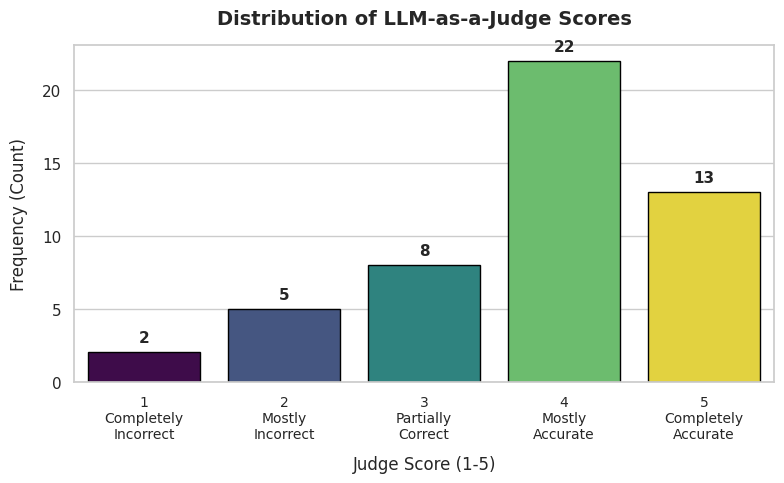

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Convert your evaluation results to a pandas DataFrame
df_results = pd.DataFrame(evaluation_results)

# 2. Filter out any parsing errors (empty strings or None values)
# Convert remaining scores to integers to ensure correct plotting
valid_scores = pd.to_numeric(df_results['score'], errors='coerce').dropna().astype(int)

# 3. Create the frequency diagram
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Use a countplot since scores are discrete integers (1, 2, 3, 4, 5)
ax = sns.countplot(
    x=valid_scores,
    hue=valid_scores,
    palette="viridis",
    legend=False,
    edgecolor="black"
)

# 4. Add frequency labels on top of each bar
for p in ax.patches:
    height = p.get_height()
    if height > 0: # Only label bars that have data
        ax.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold',
            xytext=(0, 5),
            textcoords='offset points'
        )

# 5. Customize chart labels and limits
plt.title("Distribution of LLM-as-a-Judge Scores", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Judge Score (1-5)", fontsize=12, labelpad=10)
plt.ylabel("Frequency (Count)", fontsize=12, labelpad=10)

# Map human-readable definitions to corresponding scores
score_labels = [
    "1\nCompletely\nIncorrect",
    "2\nMostly\nIncorrect",
    "3\nPartially\nCorrect",
    "4\nMostly\nAccurate",
    "5\nCompletely\nAccurate"
]

plt.xticks(ticks=[0, 1, 2, 3, 4], labels=score_labels, fontsize=10)

# Clean up layout and display
plt.tight_layout()
plt.show()

# **Compare retrival answer and actual via a LLM-as-a-Judge for PubmedQA (Different Model)**

In [28]:
!pip install groq
!pip install langchain langchain-core

In [29]:
from groq import Groq
#Please your own api key
client = Groq(api_key="")

completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
        {
            "role": "user",
            "content": "Explain quantum computing in one short sentence."
        }
    ]
)

print(completion.choices[0].message.content)

Quantum computing harnesses quantum bits that can exist in superpositions and become entangled to perform certain calculations exponentially faster than classical computers.


In [ ]:
import os
import re
from groq import Groq
from langchain_core.prompts import PromptTemplate # Assuming LangChain PromptTemplate based on your code
import time

# 1. Initialize the Groq Client
# Ensure GROQ_API_KEY environment variable is set in your notebook environment
# Put your api key
client = Groq(api_key="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")

# 2. Define the precise evaluation prompt template for the Judge
judge_prompt_template = PromptTemplate.from_template("""
You are an expert medical AI judge evaluating a Retrieval-Augmented Generation (RAG) system.
Your job is to compare a generated 'System Answer' against the 'Ground Truth Answer' and evaluate its correctness, factual accuracy, and alignment.

Provide your evaluation using the following criteria:
- **Score 5**: The System Answer is completely accurate, matches the Ground Truth perfectly, and contains no contradictions.
- **Score 4**: The System Answer is mostly accurate and captures the core point, but may miss minor non-essential details.
- **Score 3**: The System Answer is partially correct but misses critical elements of the Ground Truth or includes irrelevant facts.
- **Score 2**: The System Answer is mostly incorrect or structurally misaligned with the Ground Truth.
- **Score 1**: The System Answer completely contradicts the Ground Truth or claims to not know the answer when the Ground Truth provides one.

Context Question: {question}
Ground Truth Answer: {ground_truth}
System Generated Answer: {system_answer}

Respond strictly in the following format:
[REASONING]: <Your brief explanation of why you gave this score>
[SCORE]: <An integer from 1 to 5>
""")

# 3. Function to execute the Judge pipeline via Groq API
def judge_evaluation(question, ground_truth, system_answer):
    # Construct prompt string
    formatted_prompt = judge_prompt_template.format(
        question=question,
        ground_truth=ground_truth,
        system_answer=system_answer
    )

    # Call the Groq API using the new openai/gpt-oss-120b model configuration
    completion = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[
            {"role": "user", "content": formatted_prompt}
        ],
        max_tokens=500,
        temperature=0.1  # Keeping it deterministic for consistency
    )

    # Extract the response string securely from the completions object
    generated_text = completion.choices[0].message.content or ""

    # Safely handle completions object structure
    generated_text = completion.choices[0].message.content or ""
    score = None

    # Pattern 1: Look for explicit score labels: [SCORE]: 5, **SCORE**:5, SCORE:  5, Score is 5
    score_labels = re.search(r"(?:score)\b(?:[^1-5\n]*)\b([1-5])", generated_text, re.IGNORECASE)
    if score_labels:
        score = int(score_labels.group(1))

    # Pattern 2: Look for fraction styling like 5/5 or 4 / 5
    if score is None:
        fraction_match = re.search(r"\b([1-5])\s*/\s*5\b", generated_text)
        if fraction_match:
            score = int(fraction_match.group(1))

    # Pattern 3: Fallback to the last isolated integer 1-5 in the entire text
    if score is None:
        fallback_match = re.findall(r"\b([1-5])\b", generated_text)
        if fallback_match:
            score = int(fallback_match[-1])

    # If it still fails, print the raw output so you can inspect the exact formatting
    if score is None:
        print(f"\n❌ [PARSING ERROR] Failed on raw string:\n{repr(generated_text)}\n")


    return generated_text, score


# =====================================================================
# 4. Batch Evaluation Loop
# =====================================================================

evaluation_results = []
total_score = 0
scored_questions_count = 0

total_questions = len(target_questions)
print(f"Starting batch RAG generation and API Judge evaluation for {total_questions} questions...\n")

for q_id in range(total_questions):
    # Dynamically extract test indices
    test_question = questions_pubmed[q_id]
    test_ground_truth = answers_pubmed[q_id]
    test_system_answer = results[q_id]["answer"]

    print(f"--- Requesting API Judge Evaluation for ID {q_id} ---")

    try:
        judge_feedback, final_score = judge_evaluation(test_question, test_ground_truth, test_system_answer)

        if final_score is not None:
            total_score += final_score
            scored_questions_count += 1
            score_display = f"{final_score}/5"
            if final_score < 3 :
                print(f"--- Question {test_question} ---")
                print(f"--- Actual answer {test_ground_truth} ---")
                print(f"--- Model answer {test_system_answer} ---")
        else:
            score_display = "Parsing Error"

    except Exception as e:
        print(f"API Error processing ID {q_id}: {e}")
        judge_feedback = f"API Error: {str(e)}"
        final_score = None
        score_display = "API Error"

    # Append data rows (safeguarded variables map)
    evaluation_results.append({
        "id": q_id,
        "question": test_question,
        "ground_truth": test_ground_truth,
        "system_answer": test_system_answer,
        "judge_feedback": judge_feedback,
        "score": final_score if final_score is not None else ""
    })

    print(f"Processed ID {q_id} | Score: {score_display}\n")
    time.sleep(2)

# 5. Output Summary Statistics
if scored_questions_count > 0:
    average_score = total_score / scored_questions_count
    print(f"=== Evaluation Complete ===")
    print(f"Successfully evaluated {scored_questions_count}/{total_questions} answers.")
    print(f"Average System Judge Score: {average_score:.2f} / 5.0")
else:
    print("Evaluation finished, but no scores could be successfully parsed.")

Starting batch RAG generation and API Judge evaluation for 50 questions...

--- Requesting API Judge Evaluation for ID 0 ---
Processed ID 0 | Score: 4/5

--- Requesting API Judge Evaluation for ID 1 ---
Processed ID 1 | Score: 4/5

--- Requesting API Judge Evaluation for ID 2 ---
--- Question Intraabdominal vascular injury: are we getting any better? ---
--- Actual answer Based on the pieces of context provided, the studies and reviews conducted suggest that advances in imaging modalities, laparoscopic techniques, and endovascular repair have introduced new options for identifying and treating intraabdominal injuries, including intraabdominal vascular injuries. These advances may have potentially led to changes in surgical practice and management, with the goal of avoiding unnecessary surgical interventions and improving patient outcomes. Additionally, the studies aim to compare current mortality rates with historic controls to assess whether these advancements have made a positive imp

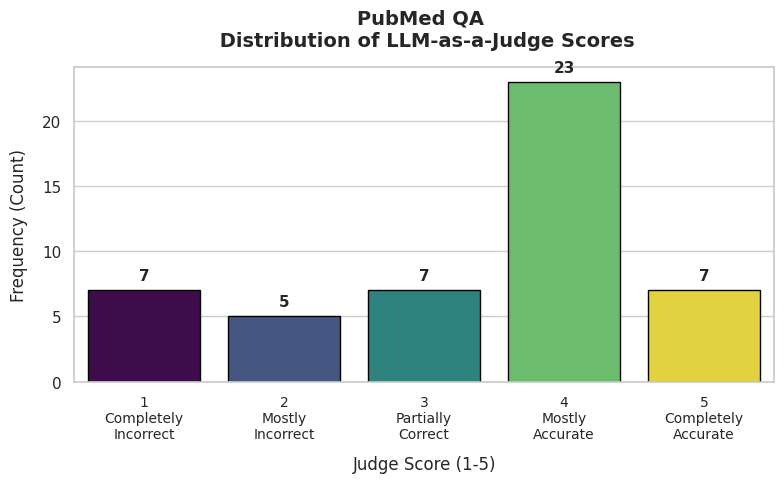

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Convert your evaluation results to a pandas DataFrame
df_results = pd.DataFrame(evaluation_results)

# 2. Filter out any parsing errors (empty strings or None values)
# Convert remaining scores to integers to ensure correct plotting
valid_scores = pd.to_numeric(df_results['score'], errors='coerce').dropna().astype(int)

# 3. Create the frequency diagram
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Use a countplot since scores are discrete integers (1, 2, 3, 4, 5)
ax = sns.countplot(
    x=valid_scores,
    hue=valid_scores,
    palette="viridis",
    legend=False,
    edgecolor="black"
)

# 4. Add frequency labels on top of each bar
for p in ax.patches:
    height = p.get_height()
    if height > 0: # Only label bars that have data
        ax.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold',
            xytext=(0, 5),
            textcoords='offset points'
        )

# 5. Customize chart labels and limits
plt.title("PubMed QA \n Distribution of LLM-as-a-Judge Scores", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Judge Score (1-5)", fontsize=12, labelpad=10)
plt.ylabel("Frequency (Count)", fontsize=12, labelpad=10)

# Map human-readable definitions to corresponding scores
score_labels = [
    "1\nCompletely\nIncorrect",
    "2\nMostly\nIncorrect",
    "3\nPartially\nCorrect",
    "4\nMostly\nAccurate",
    "5\nCompletely\nAccurate"
]

plt.xticks(ticks=[0, 1, 2, 3, 4], labels=score_labels, fontsize=10)

# Clean up layout and display
plt.tight_layout()
plt.show()

# **Compare retrival answer and actual via a LLM-as-a-Judge for CovidQA (Different Model)**

Run batch of first 50 for CovidQA

In [32]:
results = []

# Slice the questions list to only take the first 50 items
target_questions = questions_covid[:50]
print(f"Starting processing for {len(target_questions)} questions...\n")

# Loop through all questions in your list
for q_id, test_query in enumerate(target_questions):
    try:
        # 1. Retrieve the top document chunks (optional for logging, but good to keep)
        retrieved_hybrid_nodes = hybrid_retriever.invoke(test_query)

        # 2. Run the RAG chain to get the final generated response
        generation_response = rag_chain.invoke(test_query)

        # 3. Parse and clean the generated answer
        # Note: If your answers span multiple lines, remove .split("\n")[0]
        if "Answer:" in generation_response:
            clean_answer = generation_response.split("Answer:")[-1].strip().split("\n")[0]
        else:
            clean_answer = generation_response.strip().split("\n")[0]

        print(f"\nQuestion: {test_query}\n")
        print("Retrieved Chunks from Hybrid Search:")
        for i, doc in enumerate(retrieved_hybrid_nodes[:3]):
            print(f"  [{i+1}] (ID: {doc.metadata.get('chunk_id')}) -> {doc.page_content[:120]}...")

        print(f"\nGenerated Answer: {clean_answer}")

        # 4. Append the ID and Answer to our results list
        results.append({
            "id": q_id,
            "answer": clean_answer
        })

        # Optional: Print progress updates for tracking
        print(f"Processed ID {q_id}: {test_query[:30]}... -> Success")

    except Exception as e:
        print(f"Error processing ID {q_id}: {e}")
        # Append error or empty state so your IDs align correctly
        results.append({
            "id": q_id,
            "answer": "ERROR_PROCESSING"
        })

print("Processing complete.")

Starting processing for 50 questions...


Question: What role does T-cell count play in severe human adenovirus type 55 (HAdV-55) infection?

Retrieved Chunks from Hybrid Search:
  [1] (ID: 2) -> Title: Human adenovirus type 7 infection causes a more severe disease than type 3
Passage: Laboratory findings for the H...
  [2] (ID: 1) -> Title: Emergent severe acute respiratory distress syndrome caused by adenovirus type 55 in immunocompetent adults in 201...
  [3] (ID: 1999) -> Title: Emergent severe acute respiratory distress syndrome caused by adenovirus type 55 in immunocompetent adults in 201...

Generated Answer: According to the passage, patients with lower T-cell counts when admitted may have been relatively immunocompromised and that a lower T-cell count may be a risk.
Processed ID 0: What role does T-cell count pl... -> Success

Question: What is MVO?

Retrieved Chunks from Hybrid Search:
  [1] (ID: 43718) -> Managed care....
  [2] (ID: 17839) -> We asked the following questions

In [ ]:
import os
import re
from groq import Groq
from langchain_core.prompts import PromptTemplate # Assuming LangChain PromptTemplate based on your code
import time

# 1. Initialize the Groq Client
# Ensure GROQ_API_KEY environment variable is set in your notebook environment
# Put your api key
client = Groq(api_key="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")

# 2. Define the precise evaluation prompt template for the Judge
judge_prompt_template = PromptTemplate.from_template("""
You are an expert medical AI judge evaluating a Retrieval-Augmented Generation (RAG) system.
Your job is to compare a generated 'System Answer' against the 'Ground Truth Answer' and evaluate its correctness, factual accuracy, and alignment.

Provide your evaluation using the following criteria:
- **Score 5**: The System Answer is completely accurate, matches the Ground Truth perfectly, and contains no contradictions.
- **Score 4**: The System Answer is mostly accurate and captures the core point, but may miss minor non-essential details.
- **Score 3**: The System Answer is partially correct but misses critical elements of the Ground Truth or includes irrelevant facts.
- **Score 2**: The System Answer is mostly incorrect or structurally misaligned with the Ground Truth.
- **Score 1**: The System Answer completely contradicts the Ground Truth or claims to not know the answer when the Ground Truth provides one.

Context Question: {question}
Ground Truth Answer: {ground_truth}
System Generated Answer: {system_answer}

Respond strictly in the following format:
[REASONING]: <Your brief explanation of why you gave this score>
[SCORE]: <An integer from 1 to 5>
""")

# 3. Function to execute the Judge pipeline via Groq API
def judge_evaluation(question, ground_truth, system_answer):
    # Construct prompt string
    formatted_prompt = judge_prompt_template.format(
        question=question,
        ground_truth=ground_truth,
        system_answer=system_answer
    )

    # Call the Groq API using the new openai/gpt-oss-120b model configuration
    completion = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[
            {"role": "user", "content": formatted_prompt}
        ],
        max_tokens=500,
        temperature=0.1  # Keeping it deterministic for consistency
    )

    # Extract the response string securely from the completions object
    generated_text = completion.choices[0].message.content or ""

    # Safely handle completions object structure
    generated_text = completion.choices[0].message.content or ""
    score = None

    # Pattern 1: Look for explicit score labels: [SCORE]: 5, **SCORE**:5, SCORE:  5, Score is 5
    score_labels = re.search(r"(?:score)\b(?:[^1-5\n]*)\b([1-5])", generated_text, re.IGNORECASE)
    if score_labels:
        score = int(score_labels.group(1))

    # Pattern 2: Look for fraction styling like 5/5 or 4 / 5
    if score is None:
        fraction_match = re.search(r"\b([1-5])\s*/\s*5\b", generated_text)
        if fraction_match:
            score = int(fraction_match.group(1))

    # Pattern 3: Fallback to the last isolated integer 1-5 in the entire text
    if score is None:
        fallback_match = re.findall(r"\b([1-5])\b", generated_text)
        if fallback_match:
            score = int(fallback_match[-1])

    # If it still fails, print the raw output so you can inspect the exact formatting
    if score is None:
        print(f"\n❌ [PARSING ERROR] Failed on raw string:\n{repr(generated_text)}\n")


    return generated_text, score


# =====================================================================
# 4. Batch Evaluation Loop
# =====================================================================

evaluation_results = []
total_score = 0
scored_questions_count = 0

total_questions = len(target_questions)
print(f"Starting batch RAG generation and API Judge evaluation for {total_questions} questions...\n")

for q_id in range(total_questions):
    # Dynamically extract test indices
    test_question = questions_covid[q_id]
    test_ground_truth = answers_covid[q_id]
    test_system_answer = results[q_id]["answer"]

    print(f"--- Requesting API Judge Evaluation for ID {q_id} ---")

    try:
        judge_feedback, final_score = judge_evaluation(test_question, test_ground_truth, test_system_answer)

        if final_score is not None:
            total_score += final_score
            scored_questions_count += 1
            score_display = f"{final_score}/5"
            if final_score < 3 :
                print(f"--- Question {test_question} ---")
                print(f"--- Actual answer {test_ground_truth} ---")
                print(f"--- Model answer {test_system_answer} ---")
        else:
            score_display = "Parsing Error"

    except Exception as e:
        print(f"API Error processing ID {q_id}: {e}")
        judge_feedback = f"API Error: {str(e)}"
        final_score = None
        score_display = "API Error"

    # Append data rows (safeguarded variables map)
    evaluation_results.append({
        "id": q_id,
        "question": test_question,
        "ground_truth": test_ground_truth,
        "system_answer": test_system_answer,
        "judge_feedback": judge_feedback,
        "score": final_score if final_score is not None else ""
    })

    print(f"Processed ID {q_id} | Score: {score_display}\n")
    time.sleep(2)

# 5. Output Summary Statistics
if scored_questions_count > 0:
    average_score = total_score / scored_questions_count
    print(f"=== Evaluation Complete ===")
    print(f"Successfully evaluated {scored_questions_count}/{total_questions} answers.")
    print(f"Average System Judge Score: {average_score:.2f} / 5.0")
else:
    print("Evaluation finished, but no scores could be successfully parsed.")

Starting batch RAG generation and API Judge evaluation for 50 questions...

--- Requesting API Judge Evaluation for ID 0 ---
Processed ID 0 | Score: 4/5

--- Requesting API Judge Evaluation for ID 1 ---
--- Question What is MVO? ---
--- Actual answer MVO is not defined or mentioned in the provided context. It is possible that it is a typo and may refer to MV (measles virus) instead. If there is more specific information or context provided, I would be able to give a more accurate answer. ---
--- Model answer Managed care organization. ---
Processed ID 1 | Score: 1/5

--- Requesting API Judge Evaluation for ID 2 ---
--- Question What have sero-surveys of MERS virus found? ---
--- Actual answer Sero-surveys of MERS virus found no sign of MERS-CoV antibodies among patients visiting hospitals in Jeddah from 2010 through 2012, nor any sign of prior MERS-CoV infection among healthy blood donors and only 10% of strongly seropositive Canary Island in a sero-survey of livestock. They did, howev

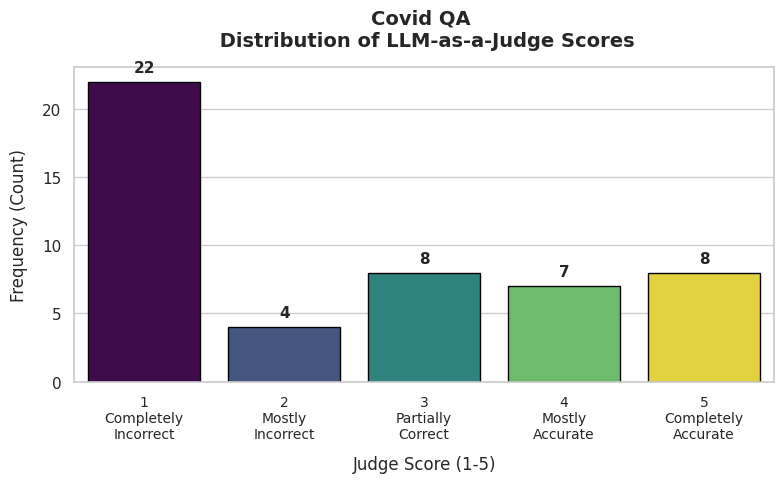

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Convert your evaluation results to a pandas DataFrame
df_results = pd.DataFrame(evaluation_results)

# 2. Filter out any parsing errors (empty strings or None values)
# Convert remaining scores to integers to ensure correct plotting
valid_scores = pd.to_numeric(df_results['score'], errors='coerce').dropna().astype(int)

# 3. Create the frequency diagram
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Use a countplot since scores are discrete integers (1, 2, 3, 4, 5)
ax = sns.countplot(
    x=valid_scores,
    hue=valid_scores,
    palette="viridis",
    legend=False,
    edgecolor="black"
)

# 4. Add frequency labels on top of each bar
for p in ax.patches:
    height = p.get_height()
    if height > 0: # Only label bars that have data
        ax.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold',
            xytext=(0, 5),
            textcoords='offset points'
        )

# 5. Customize chart labels and limits
plt.title("Covid QA \n Distribution of LLM-as-a-Judge Scores", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Judge Score (1-5)", fontsize=12, labelpad=10)
plt.ylabel("Frequency (Count)", fontsize=12, labelpad=10)

# Map human-readable definitions to corresponding scores
score_labels = [
    "1\nCompletely\nIncorrect",
    "2\nMostly\nIncorrect",
    "3\nPartially\nCorrect",
    "4\nMostly\nAccurate",
    "5\nCompletely\nAccurate"
]

plt.xticks(ticks=[0, 1, 2, 3, 4], labels=score_labels, fontsize=10)

# Clean up layout and display
plt.tight_layout()
plt.show()

## User Interface
Professional UI adapted from `Clinical_Decision_Support_v5`. Runs after the pipeline above is loaded (it uses `hybrid_retriever`, `rag_chain` and `judge_evaluation`).

The first cell writes `rag_ui.py` to disk (a self-contained Gradio app with a themed design, question triage and safety refusals, linked citations, highlighted evidence cards, session history/export, a feedback button and an **LLM-as-judge scores** tab). The cell after it is the small glue that hands our pipeline and judge to the UI via `launch_ui`:
- **Answer** tab: the generated answer with risk/type chips and the disclaimer.
- **Evidence** tab: the retrieved hybrid-search chunks, with query terms highlighted.
- **Score** tab: the batch LLM-as-a-Judge scores plus a **Score current answer** button that grades the answer on screen live.


In [41]:
!pip install -q "pillow<13.0" gradio

In [25]:
%%writefile rag_ui.py
"""
rag_ui.py - plug-in user interface for the Clinical Decision Support system (Capstone Project 3).

The UI does not care how your pipeline works. You give it ONE function:

    def my_pipeline(question: str) -> dict:
        return {
            "answer":  "",                          # optional short verdict ("yes"/"no"/"maybe"); leave blank for
                                                    #  a plain-text answer
            "reason":  "One or more sentences ...", # the answer text; [PMID 123] markers become links
            "sources": [                            # optional: the retrieved evidence, best first
                {"pmid": 21645374, "text": "chunk text ...", "section": "RESULTS", "score": 0.83,
                 "source": "PubMedQA"},
                {"id": "COVID-QA 7", "text": "chunk text ...", "source": "COVID-QA"},   # no PMID? give an id
            ],
        }

Then, in Colab (after your models are loaded):

    from rag_ui import launch_ui
    launch_ui(my_pipeline, examples=["Does metformin ...?"])   # prints a public gradio.live link

Optional question dropdown:
    launch_ui(my_pipeline,
              question_bank={"PubMedQA": [...], "COVID-QA": [...]})   # pick a dataset question to fill the box

Optional "LLM-as-judge scores" tab:
    launch_ui(my_pipeline, examples=[...],
              scores=judge_df,      # DataFrame: dataset, judge, correctness (+ question, answer, gold, reasoning)
              metrics=metrics_df,   # DataFrame of automatic metrics, shown above the judge scores
              judge_fn=live_judge)  # live_judge(question, record) -> {judge_name: {"correctness": 1-5, "reasoning": str}}

Features: question type and risk chips, safety refusals, linked citations,
evidence cards with highlighted search terms and score bars, session history with a
Markdown download, a "was this answer correct?" button that logs feedback to a CSV
(useful for the human evaluation sample), and an LLM-as-judge scores tab.

Requirements: pip install gradio      Preview without a pipeline:  python rag_ui.py
"""
import csv
import html
import inspect
import os
import re
import tempfile
import time
from datetime import datetime

import gradio as gr

DISCLAIMER = ("Research support only. This assistant summarises published abstracts; it does not diagnose, "
              "prescribe or replace clinical judgement.")

# ============================================================================ triage and safety
_TYPES = {
    "Dosage": r"\b(dose|dosage|mg|how much|titrat)",
    "Drug interaction": r"\b(interact|together with|combined with|concomitant|contraindicat)",
    "Symptoms": r"\b(symptom|sign|present with|manifest)",
    "Treatment": r"\b(treat|therapy|management|first-line|second-line|surgery)",
}
_HIGH_RISK = r"\b(dose|dosage|pregnan|breastfeed|child|infant|overdose|interact|contraindicat|stop taking|switch)"
_REFUSE = (r"\b(prescribe|prescription for|do i have|diagnose me|should i take|what should i take|"
           r"my (?:son|daughter|child|wife|husband|mother|father) has)")


def triage(question):
    q = question.lower()
    qtype = next((name for name, pat in _TYPES.items() if re.search(pat, q)), "Research question")
    risk = "refuse" if re.search(_REFUSE, q) else ("high" if re.search(_HIGH_RISK, q) else "low")
    return qtype, risk


# ============================================================================ styling
CSS = """
.ce-header {padding: 8px 4px 4px}
.ce-header h1 {margin: 0; font-size: 1.9rem; letter-spacing: -0.01em}
.ce-header p {margin: 6px 0 0; opacity: .8}
.ce-pills {display: flex; flex-wrap: wrap; gap: 8px; margin-top: 12px}
.ce-pill {font-size: .8rem; padding: 3px 10px; border-radius: 999px; border: 1px solid var(--border-color-primary)}
.ce-note {font-size: .8rem; opacity: .75; margin-top: 10px}
.ce-card {background: var(--block-background-fill); border: 1px solid var(--border-color-primary);
          border-radius: 14px; padding: 18px 20px}
.ce-empty {opacity: .65; text-align: center; padding: 36px 12px}
.ce-row {display: flex; flex-wrap: wrap; align-items: center; gap: 8px}
.ce-badge {display: inline-block; padding: 5px 18px; border-radius: 999px; font-weight: 700; font-size: 1.15rem;
           letter-spacing: .03em}
.ce-yes {background: #d8f2e6; color: #0d5a3c} .ce-no {background: #fbe0dd; color: #8a2a20}
.ce-maybe {background: #fbeccf; color: #74490a}
.ce-chip {font-size: .78rem; padding: 3px 10px; border-radius: 999px; background: var(--background-fill-secondary);
          border: 1px solid var(--border-color-primary)}
.ce-headline {font-size: 1.15rem; font-weight: 650; margin: 2px 0}
.ce-reason {line-height: 1.6; margin: 14px 0 6px; font-size: 1rem}
.ce-cites {display: flex; flex-wrap: wrap; gap: 6px; margin-top: 10px}
.ce-cite {font-size: .82rem; padding: 3px 10px; border-radius: 8px; background: #e3f0ef; color: #12514d !important;
          text-decoration: none !important}
.ce-alert {border-radius: 10px; padding: 10px 14px; margin-bottom: 14px; font-size: .92rem}
.ce-warn {background: #fbeccf; color: #74490a} .ce-stop {background: #fbe0dd; color: #8a2a20}
.ce-meta {font-size: .78rem; opacity: .65; margin-top: 12px}
.ce-src {background: var(--block-background-fill); border: 1px solid var(--border-color-primary);
         border-radius: 12px; padding: 12px 14px; margin-bottom: 10px}
.ce-src.cited {border-left: 4px solid #2a8a82}
.ce-src-head {display: flex; align-items: center; gap: 8px; flex-wrap: wrap; font-size: .82rem}
.ce-rank {display: inline-flex; width: 22px; height: 22px; border-radius: 50%; align-items: center;
          justify-content: center; background: #2a8a82; color: #fff; font-size: .75rem; font-weight: 700}
.ce-bar {height: 5px; border-radius: 3px; background: var(--background-fill-secondary); margin: 8px 0}
.ce-bar > div {height: 5px; border-radius: 3px; background: #2a8a82}
.ce-src-text {font-size: .9rem; line-height: 1.55}
.ce-src mark {background: #fde68a; color: #1f2937; padding: 0; border-radius: 2px}
.ce-reason a {padding: 0 !important; margin: 0 !important}
.ce-src summary {cursor: pointer; font-size: .8rem; opacity: .75; margin-top: 4px}
.ce-hist {font-size: .85rem; padding: 6px 0; border-bottom: 1px solid var(--border-color-primary)}
.ce-src-label {font-size: .82rem; padding: 3px 10px; border-radius: 8px; background: var(--background-fill-secondary);
               border: 1px solid var(--border-color-primary)}
.ce-jgrid {display: grid; grid-template-columns: repeat(auto-fit, minmax(210px, 1fr)); gap: 10px}
.ce-jcard {background: var(--block-background-fill); border: 1px solid var(--border-color-primary);
           border-radius: 12px; padding: 12px 14px}
.ce-jcard h4 {margin: 0 0 2px; font-size: .95rem} .ce-jcard .sub {font-size: .78rem; opacity: .7}
.ce-jnum {font-size: 1.6rem; font-weight: 700; font-variant-numeric: tabular-nums}
.ce-jlbl {font-size: .75rem; opacity: .7; text-transform: uppercase; letter-spacing: .04em}
.ce-jrow {display: flex; gap: 18px; margin-top: 6px}
.ce-dist {display: flex; align-items: flex-end; gap: 4px; height: 54px; margin-top: 10px}
.ce-dist div {flex: 1; background: #2a8a82; border-radius: 3px 3px 0 0; min-height: 2px; position: relative}
.ce-dist span {position: absolute; bottom: -16px; left: 0; right: 0; text-align: center; font-size: .7rem; opacity: .7}
.ce-section {font-weight: 650; margin: 16px 0 8px}
.ce-mtable {width: 100%; border-collapse: collapse; font-size: .85rem; font-variant-numeric: tabular-nums}
.ce-mtable th, .ce-mtable td {text-align: left; padding: 6px 8px; border-bottom: 1px solid var(--border-color-primary)}
"""

THEME = gr.themes.Soft(primary_hue="teal", neutral_hue="slate",
                       font=[gr.themes.GoogleFont("IBM Plex Sans"), "Arial", "sans-serif"])

# ============================================================================ helpers
_STOP = set("does do did is are was were the a an of in on for to with and or than that this be by from at as it "
            "its can there their have has had not after before between during into among versus vs".split())


def _link(pmid, label=None):
    """A PubMed link for a numeric PMID; a plain label for any other id (e.g. 'COVID-QA 7')."""
    pid = str(pmid).strip()
    if pid.isdigit():
        return (f'<a class="ce-cite" href="https://pubmed.ncbi.nlm.nih.gov/{pid}/" target="_blank">'
                f'{label or f"PMID {pid}"}</a>')
    return f'<span class="ce-src-label">{html.escape(label or pid)}</span>'


def _key(source):
    """The id a source is cited by: its PMID if it has one, otherwise its 'id'."""
    return str(source.get("pmid") or source.get("id") or "").strip()


def _linkify(text):
    text = html.escape(text)
    text = re.sub(r"\[?PMID[:\s]*(\d{5,9})\]?",
                  lambda m: f'<a href="https://pubmed.ncbi.nlm.nih.gov/{m.group(1)}/" target="_blank">PMID {m.group(1)}</a>',
                  text)
    return text.replace("\n", "<br>")


def _highlight(text, question):
    words = {w for w in re.findall(r"[A-Za-z][A-Za-z0-9-]{3,}", question) if w.lower() not in _STOP}
    out = html.escape(text)
    if words:
        pat = re.compile(r"\b((?:" + "|".join(re.escape(w) for w in sorted(words, key=len, reverse=True)) + r")[\w-]*)",
                         re.IGNORECASE)
        out = pat.sub(r"<mark>\1</mark>", out)
    return out


def normalise(result):
    """Accept a dict or plain text from the pipeline and return a clean dict."""
    if not isinstance(result, dict):
        result = {"answer": "", "reason": str(result)}
    ans = str(result.get("answer", "") or "").strip()
    low = ans.lower().strip(".")
    low = {"true": "yes", "false": "no"}.get(low, low)
    sources = [s if isinstance(s, dict) else {"text": str(s)} for s in (result.get("sources") or [])]
    raw = result.get("cited") or []
    if isinstance(raw, str):
        raw = [c for c in re.split(r"[,;]", raw)]
    cited = []
    for c in raw:
        c = re.sub(r"^\[?\s*PMID[:\s]*", "", str(c).strip()).strip("[] ")
        if c and c not in cited:
            cited.append(c)
    return {"verdict": low if low in ("yes", "no", "maybe") else "", "headline": "" if low in ("yes", "no", "maybe") else ans,
            "reason": str(result.get("reason", "") or ""), "sources": sources, "cited": cited}


# ============================================================================ HTML blocks
def _empty(msg):
    return f'<div class="ce-card ce-empty">{msg}</div>'


def answer_html(res, qtype, risk, secs):
    parts = ['<div class="ce-card">']
    if risk == "high":
        parts.append('<div class="ce-alert ce-warn">High-risk topic. A clinician must review this answer '
                     'before any use.</div>')
    row = ['<div class="ce-row">']
    if res["verdict"]:
        row.append(f'<span class="ce-badge ce-{res["verdict"]}">{res["verdict"].upper()}</span>')
    row.append(f'<span class="ce-chip">{html.escape(qtype)}</span>')
    row.append(f'<span class="ce-chip">Risk: {risk}</span>')
    row.append(f'<span class="ce-chip">{len(res["sources"])} sources</span></div>')
    parts.append("".join(row))
    if res["headline"]:
        parts.append(f'<div class="ce-headline" style="margin-top:12px">{html.escape(res["headline"])}</div>')
    if res["reason"]:
        parts.append(f'<div class="ce-reason">{_linkify(res["reason"])}</div>')
    if res["cited"]:
        parts.append('<div class="ce-cites"><span style="font-size:.82rem;opacity:.75">Cited:</span>'
                     + "".join(_link(p) for p in res["cited"]) + "</div>")
        retrieved = {_key(s) for s in res["sources"] if _key(s)}
        missing = [p for p in res["cited"] if retrieved and p not in retrieved]
        if missing:
            parts.append(f'<div class="ce-alert ce-stop" style="margin-top:12px">Cited sources that were not in the '
                         f'retrieved evidence: {html.escape(", ".join(missing))}</div>')
    parts.append(f'<div class="ce-meta">Answered in {secs:.1f} s - {DISCLAIMER}</div></div>')
    return "".join(parts)


def sources_html(res, question):
    if not res["sources"]:
        return _empty("No evidence returned by the pipeline.")
    scores = [float(s["score"]) for s in res["sources"] if s.get("score") is not None]
    top = max(scores) if scores else 0
    cards = []
    for i, s in enumerate(res["sources"], 1):
        key = _key(s)
        is_cited = bool(key) and key in res["cited"]
        head = [f'<span class="ce-rank">{i}</span>']
        if key:
            head.append(_link(key))
        if s.get("source"):
            head.append(f'<span class="ce-chip">{html.escape(str(s["source"]))}</span>')
        if s.get("section"):
            head.append(f'<span class="ce-chip">{html.escape(str(s["section"]))}</span>')
        if s.get("score") is not None:
            head.append(f'<span style="opacity:.7">score {float(s["score"]):.3f}</span>')
        if is_cited:
            head.append('<span class="ce-chip" style="background:#d8f2e6;color:#0d5a3c">cited</span>')
        bar = ""
        if s.get("score") is not None and top > 0:
            bar = f'<div class="ce-bar"><div style="width:{max(4, 100 * float(s["score"]) / top):.0f}%"></div></div>'
        text = str(s.get("text", ""))
        if len(text) > 420:
            cut = text[:420].rsplit(" ", 1)[0]
            body = (f'{_highlight(cut, question)}...<details><summary>Show full text</summary>'
                    f'{_highlight(text, question)}</details>')
        else:
            body = _highlight(text, question)
        cards.append(f'<div class="ce-src{" cited" if is_cited else ""}"><div class="ce-src-head">{"".join(head)}</div>'
                     f'{bar}<div class="ce-src-text">{body}</div></div>')
    return "".join(cards)


def history_html(history):
    if not history:
        return '<div style="opacity:.6;font-size:.85rem">Your questions this session appear here.</div>'
    rows = []
    for h in reversed(history[-10:]):
        tag = h["verdict"].upper() if h["verdict"] else (h["headline"][:30] or h["reason"][:30] or "-")
        rows.append(f'<div class="ce-hist"><b>{html.escape(tag)}</b> - {html.escape(h["question"])}</div>')
    return "".join(rows)


# ============================================================================ LLM-as-judge tab
def _fmt(v, nd=2):
    try:
        v = float(v)
    except (TypeError, ValueError):
        return "-"
    return "-" if v != v else f"{v:.{nd}f}"   # v != v is True only for NaN


def _table_html(df):
    """A small, theme-aware HTML table for a pandas DataFrame."""
    if df is None or len(df) == 0:
        return ""
    df = df.reset_index() if df.index.name or getattr(df.index, "names", [None])[0] else df
    head = "".join(f"<th>{html.escape(str(c))}</th>" for c in df.columns)
    body = "".join("<tr>" + "".join(f"<td>{html.escape(_fmt(v, 3) if isinstance(v, float) else str(v))}</td>"
                                    for v in row) + "</tr>" for row in df.itertuples(index=False))
    return f'<div style="overflow-x:auto"><table class="ce-mtable"><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table></div>'


def judge_summary_html(scores, metrics=None):
    """Cards: mean judge correctness per dataset and judge, with a 1-5 distribution."""
    parts = []
    if metrics is not None and len(metrics):
        parts.append('<div class="ce-section">Automatic metrics</div>' + _table_html(metrics))
    if scores is None or len(scores) == 0:
        parts.append(_empty("No judge scores yet. Run the evaluation section of the notebook first."))
        return "".join(parts)
    parts.append('<div class="ce-section">LLM-as-judge correctness (mean score, 1-5)</div><div class="ce-jgrid">')
    for (ds, judge), g in scores.groupby(["dataset", "judge"], sort=False):
        corr = g["correctness"].astype(float)
        counts = [int((corr == k).sum()) for k in range(1, 6)]
        top = max(counts) or 1
        bars = "".join(f'<div style="height:{max(4, 100 * c / top):.0f}%" title="{c} answers scored {k}"><span>{k}</span></div>'
                       for k, c in zip(range(1, 6), counts))
        parts.append(f'<div class="ce-jcard"><h4>{html.escape(str(ds))}</h4><div class="sub">{html.escape(str(judge))} - '
                     f'{corr.notna().sum()} answers</div><div class="ce-jrow">'
                     f'<div><div class="ce-jnum">{_fmt(corr.mean())}</div><div class="ce-jlbl">Correctness</div></div></div>'
                     f'<div class="ce-dist">{bars}</div><div class="sub" style="margin-top:20px">Correctness scores 1-5</div></div>')
    parts.append("</div>")
    return "".join(parts)


def live_judge_html(result):
    if not result:
        return ""
    if "correctness" in result or "error" in result:   # a single judge
        result = {"Judge": result}
    cards = []
    for name, r in result.items():
        if not isinstance(r, dict) or r.get("error"):
            msg = r.get("error") if isinstance(r, dict) else r
            cards.append(f'<div class="ce-jcard"><h4>{html.escape(str(name))}</h4><div class="sub">'
                         f'Could not score: {html.escape(str(msg))[:200]}</div></div>')
            continue
        cards.append(f'<div class="ce-jcard"><h4>{html.escape(str(name))}</h4><div class="ce-jrow">'
                     f'<div><div class="ce-jnum">{_fmt(r.get("correctness"), 0)}/5</div><div class="ce-jlbl">Correctness</div></div>'
                     f'</div><div class="sub" style="margin-top:8px">{html.escape(str(r.get("reasoning", "")))}</div></div>')
    return '<div class="ce-jgrid">' + "".join(cards) + "</div>"


# ============================================================================ the app
DEFAULT_SUBTITLE = ("Ask a biomedical research question. Answers come only from retrieved research articles, "
                    "with the evidence shown alongside.")


def _bank_choices(question_bank):
    """Flatten {dataset: [questions]} into dropdown labels like '[PubMedQA #3] ...'."""
    choices = []
    for ds_name, qs in (question_bank or {}).items():
        choices += [f"[{ds_name} #{i}] {str(qtext)}" for i, qtext in enumerate(qs)]
    return choices


def build_ui(pipeline, examples=None, title="Clinical Decision Support", safety=True,
             feedback_path="feedback.csv", subtitle=DEFAULT_SUBTITLE, scores=None, metrics=None, judge_fn=None,
             question_bank=None):
    """Return a Gradio Blocks app around `pipeline(question) -> dict`.

    scores        : optional DataFrame of LLM-as-judge results (dataset, judge, correctness,
                    and optionally question, answer, gold, reasoning). Shown in the "LLM-as-judge scores" tab.
    metrics       : optional DataFrame of automatic metrics, shown above the judge scores.
    judge_fn      : optional judge_fn(question, record) -> {judge_name: {"correctness", "reasoning"}} that scores
                    the answer currently on screen.
    question_bank : optional {dataset_name: [questions]}; shown as a dropdown that fills the question box.
    """
    show_judge = scores is not None or metrics is not None or judge_fn is not None
    detail_cols = [c for c in ["dataset", "judge", "correctness", "question", "answer", "gold",
                               "reasoning"] if scores is not None and c in scores.columns]
    bank_choices = _bank_choices(question_bank)

    def filter_scores(ds, judge):
        if scores is None:
            return None
        df = scores
        if ds and ds != "All":
            df = df[df["dataset"] == ds]
        if judge and judge != "All":
            df = df[df["judge"] == judge]
        return df[detail_cols]

    def score_current(record):
        if not record:
            return _empty("Ask a question first, then score its answer.")
        if judge_fn is None:
            return _empty("No live judge was passed to the UI.")
        try:
            return live_judge_html(judge_fn(record["question"], record))
        except Exception as e:
            return f'<div class="ce-alert ce-stop">The judge raised an error: {html.escape(str(e))}</div>'

    def ask(question, history):
        question = (question or "").strip()
        if not question:
            return _empty("Type a question to begin."), _empty("Evidence will appear here."), history, \
                history_html(history), None, ""
        qtype, risk = triage(question) if safety else ("Research question", "low")
        if risk == "refuse":
            msg = ('<div class="ce-card"><div class="ce-alert ce-stop">Not answered. This looks like a request '
                   'for a personal diagnosis or prescription. The assistant only summarises research evidence; '
                   'please consult a clinician.</div></div>')
            return msg, _empty("No evidence retrieved."), history, history_html(history), None, ""
        t0 = time.time()
        try:
            res = normalise(pipeline(question))
        except Exception as e:
            msg = f'<div class="ce-card"><div class="ce-alert ce-stop">The pipeline raised an error: {html.escape(str(e))}</div></div>'
            return msg, _empty("No evidence."), history, history_html(history), None, ""
        secs = time.time() - t0
        record = {"question": question, "time": datetime.now().strftime("%Y-%m-%d %H:%M"), **res}
        history = (history or []) + [record]
        return answer_html(res, qtype, risk, secs), sources_html(res, question), history, \
            history_html(history), record, ""

    def save_feedback(rating, comment, record):
        if not record:
            return "Ask a question first."
        new = not os.path.exists(feedback_path)
        with open(feedback_path, "a", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            if new:
                w.writerow(["time", "question", "verdict", "headline", "reason", "cited", "rating", "comment"])
            w.writerow([record["time"], record["question"], record["verdict"], record["headline"], record["reason"],
                        " ".join(map(str, record["cited"])), rating, comment or ""])
        return f"Saved: {rating}. Thank you."

    def export(history):
        if not history:
            return None
        lines = [f"# {title}: session export", "", DISCLAIMER, ""]
        for i, h in enumerate(history, 1):
            lines += [f"## {i}. {h['question']}", "",
                      f"**Answer:** {h['verdict'].upper() if h['verdict'] else (h['headline'] or h['reason'])}", "", h["reason"], "",
                      "**Cited:** " + (", ".join(f"PMID {p}" if p.isdigit() else p for p in h["cited"]) or "none"),
                      "", "**Evidence:**"]
            lines += [f"- {('PMID ' + _key(s)) if _key(s).isdigit() else (_key(s) or '?')} "
                      f"({s.get('source', '') or s.get('section', '')}): {str(s.get('text', ''))[:300]}"
                      for s in h["sources"]] + [""]
        path = os.path.join(tempfile.gettempdir(), f"assistant_session_{datetime.now():%Y%m%d_%H%M}.md")
        with open(path, "w", encoding="utf-8") as f:
            f.write("\n".join(lines))
        return path

    blocks_kwargs = {"title": title}
    if "css" in inspect.signature(gr.Blocks.__init__).parameters:   # Gradio 4/5 take css/theme here; 6 in launch()
        blocks_kwargs.update(css=CSS, theme=THEME)

    with gr.Blocks(**blocks_kwargs) as demo:
        gr.HTML(f"""<div class="ce-header"><h1>Clinical Decision Support: {html.escape(title)}</h1>
            <p>{html.escape(subtitle)}</p>
            <div class="ce-pills"><span class="ce-pill">Grounded in research articles</span><span class="ce-pill">Shows the
            evidence</span><span class="ce-pill">Flags high-risk topics</span><span class="ce-pill">Refuses diagnosis
            and prescriptions</span></div></div>""")
        history = gr.State([])
        last = gr.State(None)
        with gr.Row(equal_height=False):
            with gr.Column(scale=2, min_width=300):
                if bank_choices:
                    sample_dd = gr.Dropdown(choices=bank_choices, value=None, interactive=True,
                                            label="Pick a question from the datasets")
                q = gr.Textbox(label="Your question", lines=3, autofocus=True,
                               placeholder="e.g. Does metformin reduce cardiovascular events in type 2 diabetes?")
                if bank_choices:
                    sample_dd.change(lambda s: s.split("] ", 1)[-1] if s else "", sample_dd, q)
                with gr.Row():
                    ask_btn = gr.Button("Ask", variant="primary", scale=3)
                    clear_btn = gr.Button("Clear", scale=1)
                if examples:
                    gr.Examples(examples, inputs=q, label="Try an example")
                with gr.Accordion("Was this answer correct?", open=False):
                    comment = gr.Textbox(label="Comment (optional)", lines=2)
                    with gr.Row():
                        up = gr.Button("Correct")
                        down = gr.Button("Wrong")
                    fb_status = gr.Markdown()
                with gr.Accordion("Session history", open=False):
                    hist_box = gr.HTML(history_html([]))
                    export_btn = gr.Button("Download session (.md)", size="sm")
                    export_file = gr.File(label="Export", visible=True)
            with gr.Column(scale=3, min_width=320):
                with gr.Tabs():
                    with gr.Tab("Answer"):
                        out_answer = gr.HTML(_empty("Your answer will appear here."))
                    with gr.Tab("Evidence"):
                        out_sources = gr.HTML(_empty("Retrieved evidence will appear here."))
                    if show_judge:
                        with gr.Tab("Score"):
                            if judge_fn is not None:
                                gr.HTML('<div class="ce-section" style="margin-top:4px">Score the answer on screen</div>')
                                live_btn = gr.Button("Score current answer", size="sm")
                                live_out = gr.HTML()
                            # gr.HTML(judge_summary_html(scores, metrics))
                            '''
                            if scores is not None and len(scores):
                                gr.HTML('<div class="ce-section">Every judged answer</div>')
                                with gr.Row():
                                    ds_pick = gr.Dropdown(["All"] + sorted(scores["dataset"].astype(str).unique()),
                                                          value="All", label="Dataset")
                                    j_pick = gr.Dropdown(["All"] + sorted(scores["judge"].astype(str).unique()),
                                                         value="All", label="Judge")
                                df_kwargs = {"wrap": True, "interactive": False}
                                if "column_widths" in inspect.signature(gr.Dataframe.__init__).parameters:
                                    widths = {"dataset": "100px", "judge": "120px", "correctness": "95px",
                                              "question": "260px", "answer": "260px",
                                              "gold": "260px", "reasoning": "260px"}
                                    df_kwargs["column_widths"] = [widths.get(c, "150px") for c in detail_cols]
                                table = gr.Dataframe(filter_scores("All", "All"), **df_kwargs)
                                ds_pick.change(filter_scores, [ds_pick, j_pick], table)
                                j_pick.change(filter_scores, [ds_pick, j_pick], table)
                            '''

        outputs = [out_answer, out_sources, history, hist_box, last, fb_status]
        ask_btn.click(ask, [q, history], outputs)
        q.submit(ask, [q, history], outputs)
        clear_btn.click(lambda: ("", _empty("Your answer will appear here."),
                                 _empty("Retrieved evidence will appear here."), None, ""),
                        None, [q, out_answer, out_sources, last, fb_status])
        up.click(lambda c, r: save_feedback("correct", c, r), [comment, last], fb_status)
        down.click(lambda c, r: save_feedback("wrong", c, r), [comment, last], fb_status)
        export_btn.click(export, history, export_file)
        if show_judge and judge_fn is not None:
            live_btn.click(score_current, last, live_out)
    return demo


def launch_ui(pipeline, examples=None, title="Clinical Decision Support", safety=True, share=True,
              feedback_path="feedback.csv", subtitle=DEFAULT_SUBTITLE, scores=None, metrics=None, judge_fn=None,
              question_bank=None, **launch_kwargs):
    """Build and start the UI. share=True prints a public gradio.live link (works in Colab)."""
    demo = build_ui(pipeline, examples=examples, title=title, safety=safety, feedback_path=feedback_path,
                    subtitle=subtitle, scores=scores, metrics=metrics, judge_fn=judge_fn, question_bank=question_bank)
    if "css" in inspect.signature(gr.Blocks.launch).parameters:
        launch_kwargs.setdefault("css", CSS)
        launch_kwargs.setdefault("theme", THEME)
    demo.launch(share=share, **launch_kwargs)
    return demo


# ============================================================================ demo mode
if __name__ == "__main__":
    def demo_pipeline(question):
        time.sleep(0.4)
        return {
            "answer": "",
            "reason": ("Demo answer. In the cited study, mitochondrial dynamics changed in step with programmed cell "
                       "death in lace plant leaves [PMID 21645374], suggesting an early role. Replace demo_pipeline "
                       "with your own function that calls your retriever and LLM."),
            "sources": [
                {"pmid": 21645374, "section": "RESULTS", "score": 0.91,
                 "text": "Mitochondrial dynamics were delineated into four categories based on distribution, motility "
                         "and membrane potential. A TUNEL assay showed fragmented nDNA in a gradient over these "
                         "mitochondrial stages during programmed cell death in the lace plant."},
                {"pmid": 18222909, "section": "BACKGROUND", "score": 0.62,
                 "text": "Programmed cell death is a fundamental process in plant development and stress responses."},
                {"pmid": 23881717, "section": "METHODS", "score": 0.41,
                 "text": "Leaves at different developmental stages were imaged using live-cell confocal microscopy."},
            ],
        }

    try:   # demo judge scores so the "LLM-as-judge scores" tab can be previewed (made-up numbers)
        import random
        import pandas as pd
        random.seed(1)
        demo_scores = pd.DataFrame([{"dataset": ds, "judge": j, "question": f"Demo question {i + 1}",
                                     "correctness": random.choice([2, 3, 4, 4, 5, 5]),
                                     "reasoning": "Demo reasoning."}
                                    for ds in ["PubMedQA", "COVID-QA"] for j in ["Llama 3.3 70B", "GPT-OSS 120B"]
                                    for i in range(50)])
        demo_metrics = pd.DataFrame({"dataset": ["PubMedQA", "COVID-QA"], "questions": [50, 50],
                                     "Recall@5": [0.96, 0.88], "token_F1": [0.44, 0.41]})
    except ImportError:
        demo_scores = demo_metrics = None

    def demo_judge(question, record):
        return {"Llama 3.3 70B": {"correctness": 5, "reasoning": "Demo: matches the reference answer."},
                "GPT-OSS 120B": {"correctness": 4, "reasoning": "Demo: mostly correct."}}

    launch_ui(demo_pipeline, share=False, scores=demo_scores, metrics=demo_metrics, judge_fn=demo_judge,
              question_bank={"PubMedQA": ["Is metformin associated with lower cancer risk in type 2 diabetes?"],
                             "COVID-QA": ["Does vitamin D reduce COVID-19 severity?"]},
              examples=[
        "Do mitochondria play a role in remodelling lace plant leaves during programmed cell death?",
        "Is metformin associated with lower cancer risk in type 2 diabetes?",
        "What dose of insulin is safe in pregnancy?"])


Writing rag_ui.py


In [26]:
from importlib import reload
import pandas as pd
import rag_ui
reload(rag_ui)

# ---------------------------------------------------------
# 1. Build the "Score" tab table from the batch evaluation results
# ---------------------------------------------------------
def _detect_dataset(q):
    try:
        if 'questions_covid' in globals() and (questions_covid == q).any():
            return "CovidQA"
    except Exception:
        pass
    try:
        if 'questions_pubmed' in globals() and (questions_pubmed == q).any():
            return "PubMedQA"
    except Exception:
        pass
    return "Dataset"

judge_rows = []
for item in (evaluation_results if 'evaluation_results' in globals() else []):
    judge_rows.append({
        "dataset": _detect_dataset(item.get("question", "")),
        "judge": "LLM-as-a-Judge",
        "correctness": item.get("score"),
        "question": item.get("question", ""),
        "answer": item.get("system_answer", ""),
        "gold": item.get("ground_truth", ""),
        "reasoning": item.get("judge_feedback", ""),
    })
judge_df = pd.DataFrame(judge_rows)

metrics_df = None
if len(judge_df):
    # ADD THIS LINE: turns "" into NaN so rag_ui.py doesn't crash
    judge_df["correctness"] = pd.to_numeric(judge_df["correctness"], errors="coerce")
    
    metrics_df = (judge_df
                  .groupby("dataset")
                  .agg(questions=("question", "count"), mean_judge_score=("correctness", "mean"))
                  .round(2))

# ---------------------------------------------------------
# 2. Hand our pipeline (hybrid retriever + RAG chain) to the UI
# ---------------------------------------------------------
def _clean_rag_answer(raw):
    if "Answer:" in raw:
        return raw.split("Answer:")[-1].strip().split("\n")[0]
    return raw.strip().split("\n")[0]

def my_pipeline(question: str) -> dict:
    docs = hybrid_retriever.invoke(question)
    raw = rag_chain.invoke(question)
    return {
        "answer": "",
        "reason": _clean_rag_answer(raw),
        "sources": [{"id": f"Chunk {d.metadata.get('chunk_id')}", "source": "Medical corpus",
                     "text": d.page_content} for d in docs],
    }

# ---------------------------------------------------------
# 3. Live LLM-as-a-Judge for the answer currently on screen
# ---------------------------------------------------------
def _lookup_ground_truth(question):
    q = (question or "").strip()
    try:
        m = questions_pubmed[questions_pubmed == q]
        if len(m):
            return answers_pubmed[m.index[0]]
    except Exception:
        pass
    try:
        m = questions_covid[questions_covid == q]
        if len(m):
            return answers_covid[m.index[0]]
    except Exception:
        pass
    return None

def live_judge(question, record):
    answer_text = " ".join(x for x in [record.get("headline", ""), record.get("reason", "")] if x).strip()
    ground_truth = _lookup_ground_truth(question)
    if ground_truth is None:   # new question: judge against the retrieved evidence instead
        ground_truth = "\n".join(str(s.get("text", "")) for s in record.get("sources", []))
    feedback, score = judge_evaluation(question, ground_truth, answer_text)
    return {"LLM-as-a-Judge": {"correctness": score, "reasoning": feedback}}

# ---------------------------------------------------------
# 4. Launch
# ---------------------------------------------------------
examples = []
try:
    examples = list(questions_pubmed[:2]) + list(questions_covid[:2])
except Exception:
    pass

# Dropdown choices: first 50 questions of each dataset (like clinical-decision-support-capstone-v1)
question_bank = {}
try:
    question_bank["PubMedQA"] = list(questions_pubmed[:50])
except Exception:
    pass
try:
    question_bank["CovidQA"] = list(questions_covid[:50])
except Exception:
    pass

demo = rag_ui.launch_ui(
    my_pipeline,
    examples=examples,
    title="Medical RAG",
    subtitle="Ask a biomedical or COVID-19 research question. Answers come only from the retrieved medical corpus, "
             "with the hybrid-search evidence shown alongside.",
    scores=(judge_df[["dataset", "judge", "correctness", "question", "answer", "gold", "reasoning"]]
            if len(judge_df) else None),
    metrics=metrics_df,
    judge_fn=live_judge,
    question_bank=question_bank,
    share=True,
)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://42ad9d8e0812785c17.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
